<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%205/MRayhanZamzami_JS05_T1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# TUGAS

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Jumlah cluster: 2
Banyaknya noise: 0


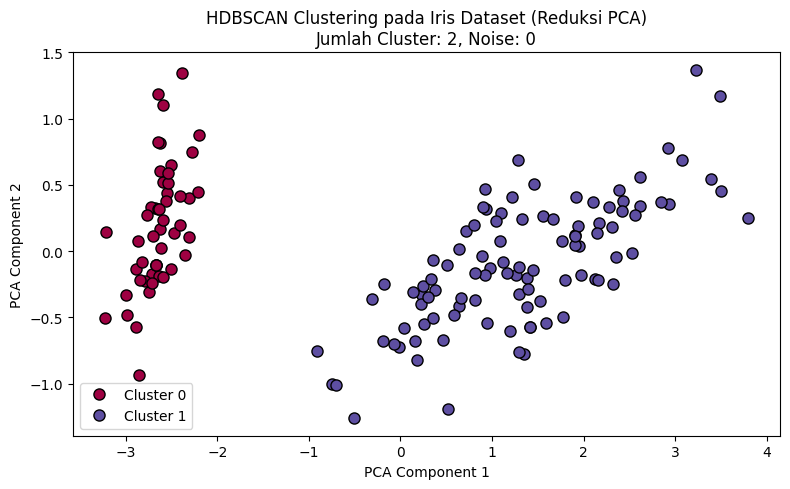


Tabel Kontingensi (Asli vs HDBSCAN):
HDBSCAN_Label     0   1
Species                
Iris-setosa      50   0
Iris-versicolor   0  50
Iris-virginica    0  50


In [6]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.cluster import HDBSCAN

from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/ml-semester5/dataset/Iris.csv')

# Membuang kolom 'Id' jika ada
if 'Id' in df.columns:
    df = df.drop('Id', axis=1)

# Memisahkan fitur dan label asli
X = df.drop('Species', axis=1).values
y_true = df['Species'].values

# Melakukan clustering dengan HDBSCAN menggunakan implementasi dari scikit-learn
clusterer = HDBSCAN(min_cluster_size=10, min_samples=5)
labels = clusterer.fit_predict(X)

# Menghitung metrik hasil clustering
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print(f"Jumlah cluster: {n_clusters}")
print(f"Banyaknya noise: {n_noise}")

# Melakukan PCA untuk reduksi dimensi menjadi 2 komponen
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Membuat visualisasi hasil HDBSCAN
plt.figure(figsize=(8, 5))
unique_labels = set(labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]  # Hitam untuk noise
    class_member_mask = (labels == k)
    xy = X_pca[class_member_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=8 if k != -1 else 5, label=f'Cluster {k}' if k != -1 else 'Noise (-1)')

plt.title(f'HDBSCAN Clustering pada Iris Dataset (Reduksi PCA)\nJumlah Cluster: {n_clusters}, Noise: {n_noise}')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend()
plt.tight_layout()
plt.savefig('hdbscan_iris_pca.png')
plt.show()

# Membuat crosstab untuk analisis kesesuaian dengan label asli
df['HDBSCAN_Label'] = labels
crosstab = pd.crosstab(df['Species'], df['HDBSCAN_Label'])
print("\nTabel Kontingensi (Asli vs HDBSCAN):")
print(crosstab)

# Analisis Singkat

Hasil clustering dari HDBSCAN tidak sepenuhnya sesuai dengan label asli dataset Iris. Dataset asli memiliki 3 kelas (Setosa, Versicolor, dan Virginica), namun HDBSCAN hanya mendeteksi 2 cluster.

Cluster 0 (50 sampel): Secara sempurna memisahkan seluruh data spesies Iris-setosa. Spesies ini memang diketahui memiliki karakteristik fitur yang sangat berbeda dan terpisah jauh dari dua spesies lainnya.

Cluster 1 (100 sampel): HDBSCAN menggabungkan seluruh sampel Iris-versicolor dan Iris-virginica ke dalam satu cluster yang sama.

Ketidaksesuaian ini wajar terjadi pada algoritma berbasis kepadatan (density-based clustering) seperti HDBSCAN. Fitur antara versicolor dan virginica memiliki sebaran data yang sangat berdekatan dan tumpang tindih (overlap). Akibatnya, kedua spesies tersebut tidak memiliki ruang "kepadatan rendah" (low-density region) yang cukup tegas untuk memisahkan mereka menjadi dua cluster berbeda, sehingga HDBSCAN menganggapnya sebagai satu area kepadatan yang sama.